# Employee Attrition Predictor with Segments

**Goal:**

(1) predict whether an employee will leave (classification), and

(2) group employees into segments (clustering) so HR can see *who* is at

risk and *why*, and act per segment.

Dataset: IBM HR Analytics Employee Attrition (1470 employees, 35 columns).

## Load the data

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/hr.csv")

df.head()


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [ ]:
df.shape

(1470, 35)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [ ]:
df.describe(include='all')

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470,1470,1470.000000,1470,1470.000000,1470.000000,1470,1470.0,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
unique,NaN,2,3,NaN,3,NaN,NaN,6,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,No,Travel_Rarely,NaN,Research & Development,NaN,NaN,Life Sciences,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1233,1043,NaN,961,NaN,NaN,606,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,36.923810,NaN,NaN,802.485714,NaN,9.192517,2.912925,NaN,1.0,1024.865306,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,NaN,NaN,403.509100,NaN,8.106864,1.024165,NaN,0.0,602.024335,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,NaN,NaN,102.000000,NaN,1.000000,1.000000,NaN,1.0,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,NaN,NaN,465.000000,NaN,2.000000,2.000000,NaN,1.0,491.250000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,NaN,NaN,802.000000,NaN,7.000000,3.000000,NaN,1.0,1020.500000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,NaN,NaN,1157.000000,NaN,14.000000,4.000000,NaN,1.0,1555.750000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000


In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df.duplicated().sum()

np.int64(0)

## Clean

Columns with only one value carry no information, and `EmployeeNumber` is just an ID.

In [ ]:
# columns that have the same value in every row
const_cols = [c for c in df.columns if df[c].nunique() == 1]
const_cols

['EmployeeCount', 'Over18', 'StandardHours']

In [ ]:
df1 = df.drop(columns=const_cols + ["EmployeeNumber"])
df1.shape

(1470, 31)

In [ ]:
print("Original Shape:", df.shape)
print("After Cleaning:", df1.shape)

print("Remaining Constant Columns:",
      [c for c in df1.columns if df1[c].nunique() == 1])

Original Shape: (1470, 35)
After Cleaning: (1470, 31)
Remaining Constant Columns: []


In [ ]:
df1["Attrition"] = df1["Attrition"].map({"No": 0, "Yes": 1})

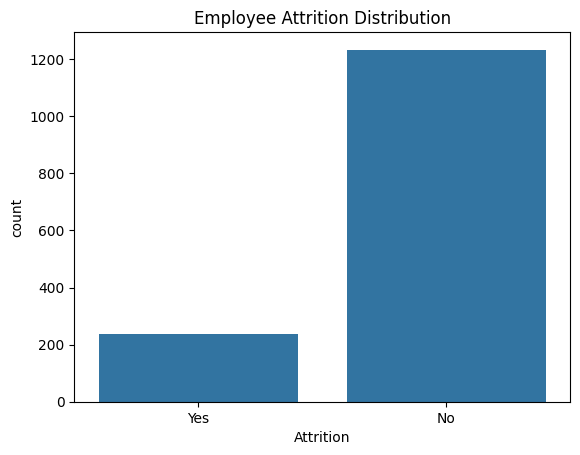

Attrition
No     1233
Yes     237
Name: count, dtype: int64
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


In [ ]:
sns.countplot(data=df, x='Attrition')

plt.title('Employee Attrition Distribution')
plt.show()

print(df['Attrition'].value_counts())
print(df['Attrition'].value_counts(normalize=True)*100)

Yes = 1 (left), No = 0 (stayed)

### Numerical features vs Attrition

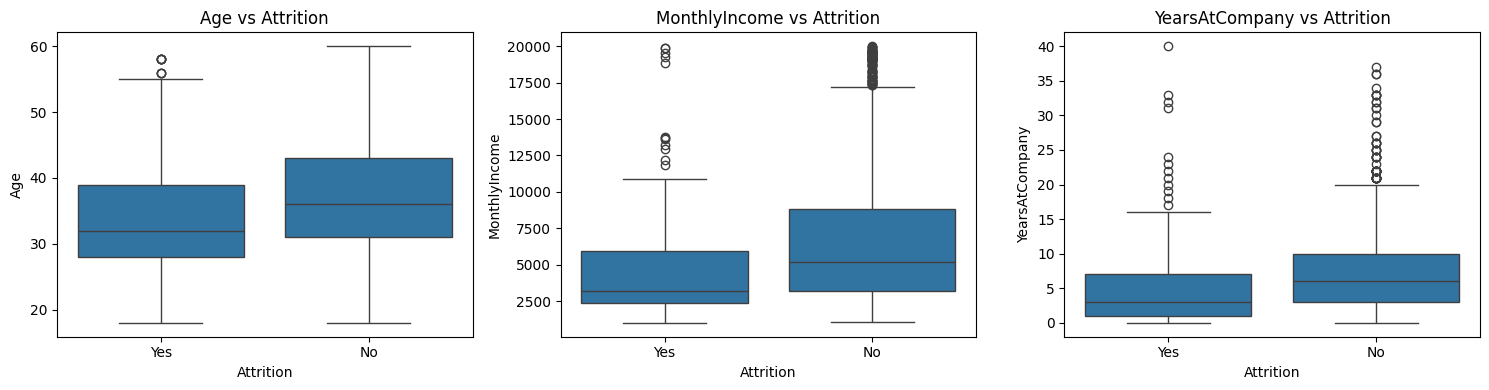

In [ ]:
plt.figure(figsize=(15,4))

features = ['Age', 'MonthlyIncome', 'YearsAtCompany']

for i, col in enumerate(features):
    plt.subplot(1,3,i+1)
    sns.boxplot(data=df, x='Attrition', y=col)
    plt.title(f'{col} vs Attrition')

plt.tight_layout()
plt.show()

### Categorical features vs Attrition

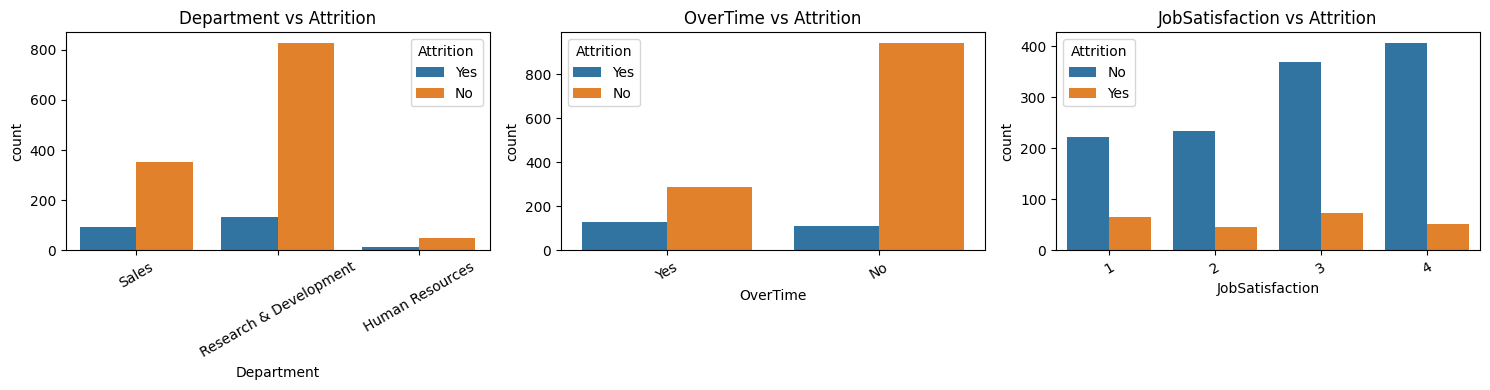

In [ ]:
plt.figure(figsize=(15,4))

features = ['Department', 'OverTime', 'JobSatisfaction']

for i, col in enumerate(features):
    plt.subplot(1,3,i+1)
    sns.countplot(data=df, x=col, hue='Attrition')
    plt.title(f'{col} vs Attrition')
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### Correlation heatmap

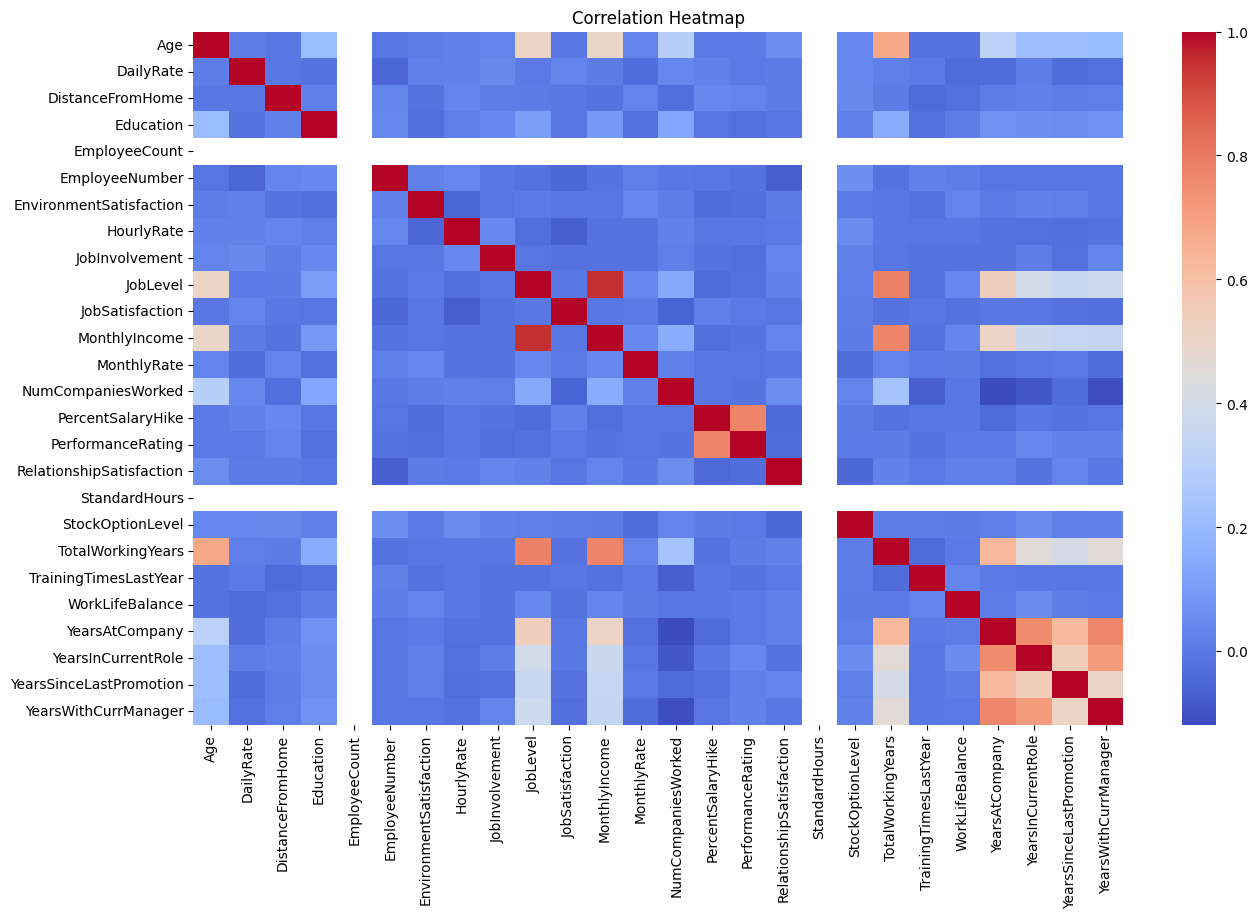

In [ ]:
plt.figure(figsize=(15,9))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    cmap='coolwarm',
    annot=False
)

plt.title('Correlation Heatmap')
plt.show()

In [ ]:
features = ['Department', 'OverTime', 'JobSatisfaction']

for col in features:

    rate = pd.crosstab(
        df[col],
        df['Attrition'],
        normalize='index'
    ) * 100

    print(f'\nAttrition percentage by {col}:')
    print(rate['Yes'])


Attrition percentage by Department:
Department
Human Resources           19.047619
Research & Development    13.839750
Sales                     20.627803
Name: Yes, dtype: float64

Attrition percentage by OverTime:
OverTime
No     10.436433
Yes    30.528846
Name: Yes, dtype: float64

Attrition percentage by JobSatisfaction:
JobSatisfaction
1    22.837370
2    16.428571
3    16.515837
4    11.328976
Name: Yes, dtype: float64


## Encoding
Machine learning needs numbers. Find the text (object) columns first.

In [ ]:
cat_cols = df1.select_dtypes(include="object").columns
cat_cols

Index(['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole',
       'MaritalStatus', 'OverTime'],
      dtype='object')

In [ ]:
for c in cat_cols:
    print("\n", c)
    print(df1[c].unique())


 BusinessTravel
['Travel_Rarely' 'Travel_Frequently' 'Non-Travel']

 Department
['Sales' 'Research & Development' 'Human Resources']

 EducationField
['Life Sciences' 'Other' 'Medical' 'Marketing' 'Technical Degree'
 'Human Resources']

 Gender
['Female' 'Male']

 JobRole
['Sales Executive' 'Research Scientist' 'Laboratory Technician'
 'Manufacturing Director' 'Healthcare Representative' 'Manager'
 'Sales Representative' 'Research Director' 'Human Resources']

 MaritalStatus
['Single' 'Married' 'Divorced']

 OverTime
['Yes' 'No']


In [ ]:
df_encoded = pd.get_dummies(df1, drop_first=True, dtype=int)
df_encoded.head()

,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,...,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes
0,41,1,1102,1,2,2,94,3,2,4,...,0,0,0,0,0,1,0,0,1,1
1,49,0,279,8,1,3,61,2,2,2,...,0,0,0,0,1,0,0,1,0,0
2,37,1,1373,2,2,4,92,2,1,3,...,1,0,0,0,0,0,0,0,1,1
3,33,0,1392,3,4,4,56,3,1,3,...,0,0,0,0,1,0,0,1,0,1
4,27,0,591,2,1,1,40,3,1,2,...,1,0,0,0,0,0,0,1,0,0


In [ ]:
print("Original Dataset Shape:", df1.shape)
print("Encoded Dataset Shape:", df_encoded.shape)

print("\nRemaining Object Columns:")
print(df_encoded.select_dtypes(include=['object']).columns.tolist())

Original Dataset Shape: (1470, 31)
Encoded Dataset Shape: (1470, 45)

Remaining Object Columns:
[]


## Define x and y

In [ ]:
x = df_encoded.drop(columns="Attrition")
x.ndim

2

In [ ]:
y = df_encoded["Attrition"]
y.ndim

1

In [ ]:
x.shape

(1470, 44)

In [ ]:
y.shape

(1470,)

## Train Test Split

In [ ]:
from sklearn.model_selection import train_test_split

xtrain, xtest, ytrain, ytest = train_test_split(
    x, y, test_size=0.30, random_state=42, stratify=y)

In [ ]:
xtrain.shape

(1029, 44)

In [ ]:
xtest.shape

(441, 44)

In [ ]:
print("train:\n", ytrain.value_counts(), "\n")
print("test:\n", ytest.value_counts())

train:
 Attrition
0    863
1    166
Name: count, dtype: int64 

test:
 Attrition
0    370
1     71
Name: count, dtype: int64


In [ ]:
# checking the ratio of leavers is the same in both
print(round(ytrain.mean(), 3), round(ytest.mean(), 3))

0.161 0.161


## SMOTE

In [ ]:
# Apply SMOTE to the training data only.

In [ ]:
from imblearn.over_sampling import SMOTE

sm = SMOTE(random_state=42)
xtrain_sm, ytrain_sm = sm.fit_resample(xtrain, ytrain)

In [ ]:
ytrain_sm.value_counts()

,count
Attrition,
0,863
1,863


## Feature scaling (StandardScaler)

In [ ]:
# Features are on very different ranges
# (MonthlyIncome in thousands, JobSatisfaction 1 to 4).
# Scaling puts them on the same scale:

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
xtrain_s = scaler.fit_transform(xtrain_sm)
xtest_s = scaler.transform(xtest)
xtrain_s[:2]

array([[-1.82629608, -0.38211274, -0.08859574, -0.72824275,  0.50499131,
        -0.52330646,  0.6264831 , -0.83256543, -1.36291832, -0.76285919,
        -1.01820709, -0.73955103,  2.96614582,  3.02538281,  0.46920002,
        -0.72932739, -1.21885799,  1.25964008,  0.5878969 , -0.8829166 ,
        -0.73846872, -0.65293244, -1.02475616, -0.40090684,  0.79556481,
         0.96582128, -0.57958029,  1.56588633, -0.28421199, -0.53043944,
        -0.1709352 , -0.26717828,  0.97708745, -0.15003949, -0.42208648,
        -0.21461735, -0.24930673, -0.17971269,  2.56323535, -0.48892986,
        -0.20406254, -0.68387651,  1.55276115, -0.63232728],
       [-0.24057497,  1.27269324,  0.70098905, -1.75264942, -0.4262213 ,
        -0.41750501,  0.6264831 ,  1.15637289,  0.49521519,  1.86835828,
         1.4001993 ,  1.86017417, -0.88671859, -0.33053668,  1.4086887 ,
        -0.72932739,  0.73293024, -0.45972629,  1.91085654,  0.23051305,
         0.76993011,  1.7573119 ,  1.09638551, -0.40090684,  0.

In [ ]:
# check: train columns now have mean ~0 and std ~1
print(xtrain_s.mean().round(3), xtrain_s.std().round(3))

-0.0 1.0


## Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix)

lr = LogisticRegression(max_iter=2000)
lr.fit(xtrain_s, ytrain_sm)
ypred = lr.predict(xtest_s)
confusion_matrix(ytest, ypred)

array([[343,  27],
       [ 39,  32]])

In [ ]:
def scores(model, name):
    pred = model.predict(xtest_s)
    proba = model.predict_proba(xtest_s)[:, 1]
    return {"Model": name, "Accuracy": accuracy_score(ytest, pred), "Recall": recall_score(ytest, pred),
            "Precision": precision_score(ytest, pred), "F1": f1_score(ytest, pred),
            "ROC-AUC": roc_auc_score(ytest, proba)}

results = [scores(lr, "Logistic Regression")]
pd.DataFrame(results).round(3)

,Model,Accuracy,Recall,Precision,F1,ROC-AUC
0,Logistic Regression,0.85,0.451,0.542,0.492,0.759


## KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(xtrain_s, ytrain_sm)
results.append(scores(knn, "KNN"))
pd.DataFrame(results).round(3)

,Model,Accuracy,Recall,Precision,F1,ROC-AUC
0,Logistic Regression,0.85,0.451,0.542,0.492,0.759
1,KNN,0.78,0.324,0.319,0.322,0.666


## Naive Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(xtrain_s, ytrain_sm)
results.append(scores(nb, "Naive Bayes"))
pd.DataFrame(results).round(3)

,Model,Accuracy,Recall,Precision,F1,ROC-AUC
0,Logistic Regression,0.850,0.451,0.542,0.492,0.759
1,KNN,0.780,0.324,0.319,0.322,0.666
2,Naive Bayes,0.603,0.577,0.220,0.319,0.612


## Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(xtrain_s, ytrain_sm)
results.append(scores(dt, "Decision Tree"))
pd.DataFrame(results).round(3)

,Model,Accuracy,Recall,Precision,F1,ROC-AUC
0,Logistic Regression,0.850,0.451,0.542,0.492,0.759
1,KNN,0.780,0.324,0.319,0.322,0.666
2,Naive Bayes,0.603,0.577,0.220,0.319,0.612
3,Decision Tree,0.723,0.451,0.278,0.344,0.631


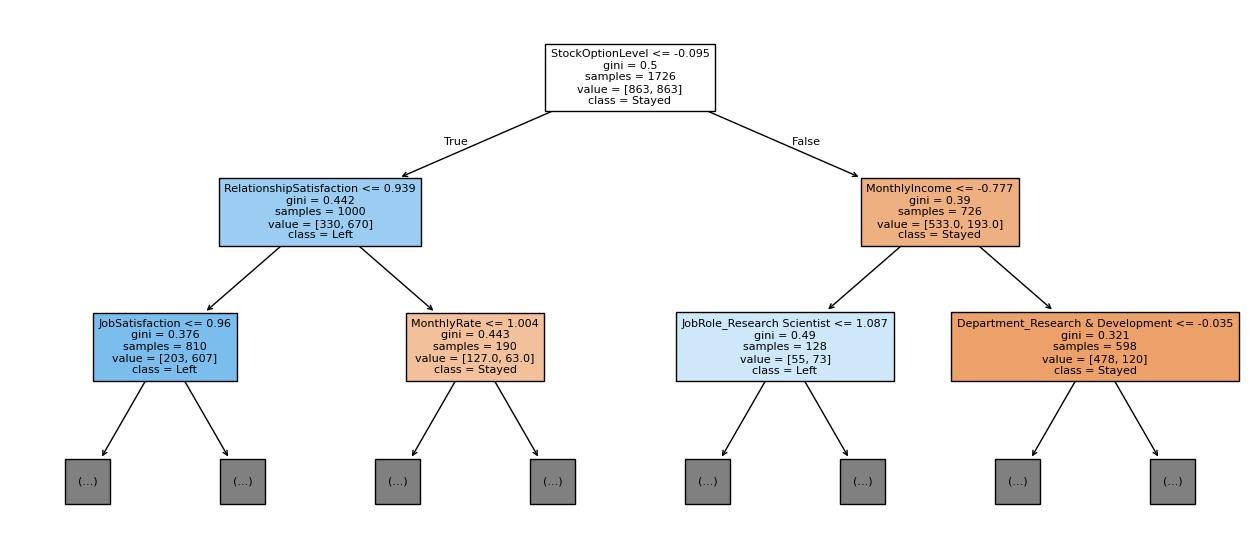

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 7))
plot_tree(dt, max_depth=2, feature_names=list(x.columns), class_names=["Stayed", "Left"], filled=True, fontsize=8)
plt.show()

## Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(xtrain_s, ytrain_sm)
results.append(scores(rf, "Random Forest"))
pd.DataFrame(results).round(3)

,Model,Accuracy,Recall,Precision,F1,ROC-AUC
0,Logistic Regression,0.850,0.451,0.542,0.492,0.759
1,KNN,0.780,0.324,0.319,0.322,0.666
2,Naive Bayes,0.603,0.577,0.220,0.319,0.612
3,Decision Tree,0.723,0.451,0.278,0.344,0.631
4,Random Forest,0.825,0.254,0.429,0.319,0.718


## XGBoost

In [ ]:
from xgboost import XGBClassifier

xgb = XGBClassifier(random_state=42, eval_metric="logloss")
xgb.fit(xtrain_s, ytrain_sm)
results.append(scores(xgb, "XGBoost"))
pd.DataFrame(results).round(3).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)

,Model,Accuracy,Recall,Precision,F1,ROC-AUC
0,Logistic Regression,0.850,0.451,0.542,0.492,0.759
1,XGBoost,0.844,0.296,0.525,0.378,0.743
2,Random Forest,0.825,0.254,0.429,0.319,0.718
3,KNN,0.780,0.324,0.319,0.322,0.666
4,Decision Tree,0.723,0.451,0.278,0.344,0.631
5,Naive Bayes,0.603,0.577,0.220,0.319,0.612


## Hyperparameter tuning (GridSearchCV)

In [ ]:
from sklearn.model_selection import GridSearchCV

model = LogisticRegression(max_iter=2000)
parameters = {"C": [0.01, 0.1, 0.5, 1, 5],
              "class_weight": [None, "balanced"]}

grid_model = GridSearchCV(model, parameters, cv=5, scoring="roc_auc")
grid_model.fit(xtrain_s, ytrain_sm)

GridSearchCV(cv=5, estimator=LogisticRegression(max_iter=2000),
             param_grid={'C': [0.01, 0.1, 0.5, 1, 5],
                         'class_weight': [None, 'balanced']},
             scoring='roc_auc')

In [ ]:
grid_model.best_params_

{'C': 0.01, 'class_weight': None}

In [ ]:
tuned = grid_model.best_estimator_

compare = pd.DataFrame([scores(lr, "Default Logistic Regression"),
                        scores(tuned, "Tuned Logistic Regression")]).round(3)
compare

,Model,Accuracy,Recall,Precision,F1,ROC-AUC
0,Default Logistic Regression,0.850,0.451,0.542,0.492,0.759
1,Tuned Logistic Regression,0.846,0.408,0.527,0.460,0.727


In [ ]:
# Tuning did not improve the model here (ROC-AUC is lower). This happens, and your notes say the same: no guarantee for improvement.
# One reason is that GridSearchCV is cross-validating on SMOTE data, where synthetic rows are copies of real ones, so its scores are too optimistic.
# So we keep the default Logistic Regression as the final model, and explain this in the report.

In [ ]:
final_model = lr
ypred = final_model.predict(xtest_s)

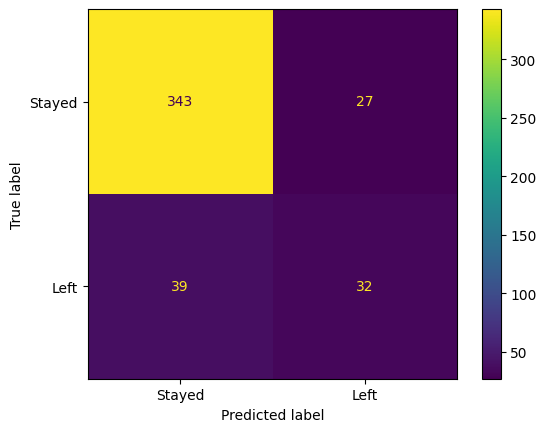

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(ytest, ypred)
ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Left"]).plot()
plt.show()

In [ ]:
print("Accuracy :", round(accuracy_score(ytest, ypred), 3))
print("Recall   :", round(recall_score(ytest, ypred), 3))
print("Precision:", round(precision_score(ytest, ypred), 3))
print("F1       :", round(f1_score(ytest, ypred), 3))

Accuracy : 0.85
Recall   : 0.451
Precision: 0.542
F1       : 0.492


## Decision threshold
By default the model says 'will leave' when probability >= 0.5. HR may prefer to catch more leavers (higher recall) and accept more false alarms.
Lower threshold = more people flagged.

In [ ]:
proba = final_model.predict_proba(xtest_s)[:, 1]

for t in [0.3, 0.4, 0.5, 0.6]:
    ypred_t = (proba >= t).astype(int)
    print(t, "recall:", round(recall_score(ytest, ypred_t), 3),
             "precision:", round(precision_score(ytest, ypred_t), 3))

0.3 recall: 0.592 precision: 0.408
0.4 recall: 0.493 precision: 0.473
0.5 recall: 0.451 precision: 0.542
0.6 recall: 0.394 precision: 0.636


## What causes attrition? (Logistic Regression coefficients)
Positive = raises chance of leaving. Negative = lowers it. (Features are scaled, so sizes are comparable.)

In [ ]:
coef = pd.Series(final_model.coef_[0], index=x.columns).sort_values()

In [ ]:
print("Raises attrition:")
print(coef.tail(8))
print("\nLowers attrition:")
print(coef.head(8))

Raises attrition:
PercentSalaryHike                   0.043060
YearsAtCompany                      0.065371
BusinessTravel_Travel_Frequently    0.236459
MonthlyIncome                       0.266512
DistanceFromHome                    0.272305
NumCompaniesWorked                  0.374320
YearsSinceLastPromotion             0.544818
OverTime_Yes                        0.678075
dtype: float64

Lowers attrition:
EducationField_Life Sciences        -1.623387
EducationField_Medical              -1.470119
Department_Research & Development   -1.318981
Department_Sales                    -0.903529
EducationField_Technical Degree     -0.800221
EducationField_Marketing            -0.796538
EducationField_Other                -0.782458
JobRole_Human Resources             -0.713738
dtype: float64


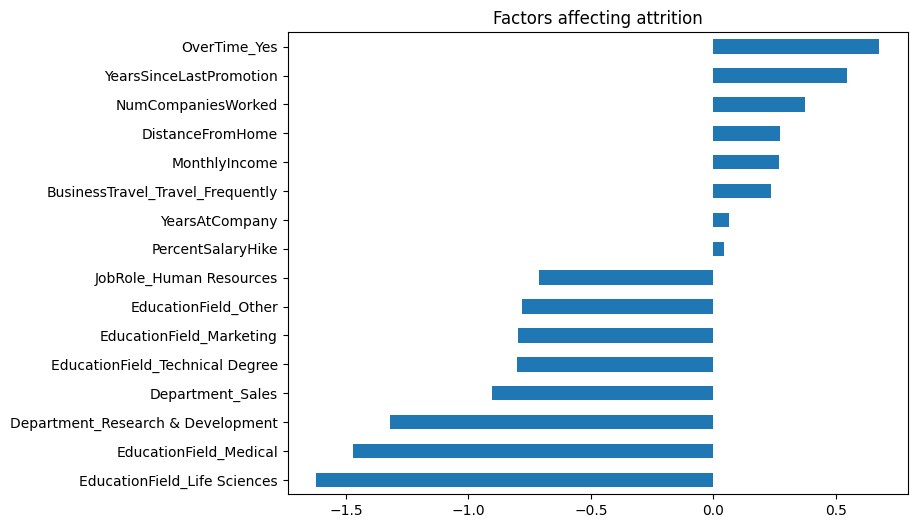

In [ ]:
top = pd.concat([coef.head(8), coef.tail(8)])
top.plot(kind="barh", figsize=(8, 6))
plt.title("Factors affecting attrition")
plt.show()

## Segments (KMeans clustering)
Classification tells us who may leave. Clustering tells us what types of employees we have. No target and no train-test split here.

In [ ]:
seg_cols = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole",
            "YearsSinceLastPromotion", "DistanceFromHome", "JobLevel", "JobSatisfaction",
            "EnvironmentSatisfaction", "WorkLifeBalance", "NumCompaniesWorked"]

seg_df = df1[seg_cols].copy()
seg_df["OverTime"] = df1["OverTime"].map({"No": 0, "Yes": 1})
seg_df.head()

,Age,MonthlyIncome,TotalWorkingYears,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,DistanceFromHome,JobLevel,JobSatisfaction,EnvironmentSatisfaction,WorkLifeBalance,NumCompaniesWorked,OverTime
0,41,5993,8,6,4,0,1,2,4,2,1,8,1
1,49,5130,10,10,7,1,8,2,2,3,3,1,0
2,37,2090,7,0,0,0,2,1,3,4,3,6,1
3,33,2909,8,8,7,3,3,1,3,4,3,1,1
4,27,3468,6,2,2,2,2,1,2,1,3,9,0


In [ ]:
scaler2 = StandardScaler()
seg_scaled = scaler2.fit_transform(seg_df)

## Elbow Method

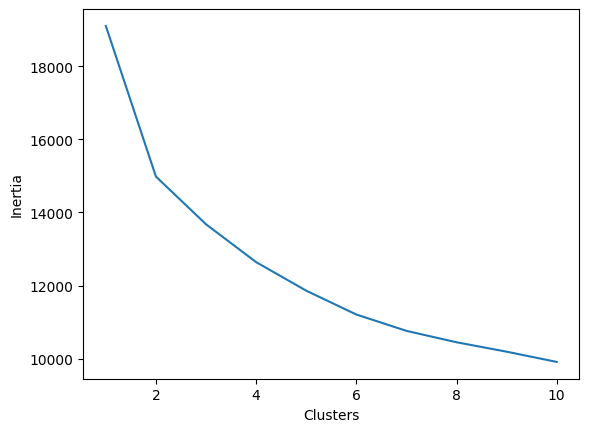

In [ ]:
from sklearn.cluster import KMeans

wcss = []
for i in range(1, 11):
    km = KMeans(n_clusters=i, init="k-means++", n_init=10, random_state=42)
    km.fit(seg_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss)
plt.xlabel("Clusters")
plt.ylabel("Inertia")
plt.show()

In [ ]:
# The elbow is not sharp, so we choose 4 clusters: enough groups to be useful for HR, but few enough to act on.

In [ ]:
kmeans = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42)
kmeans.fit(seg_scaled)

df1["Segment"] = kmeans.labels_
df1["Segment"].value_counts()

,count
Segment,
0,474
1,420
2,368
3,208


In [ ]:
from sklearn.metrics import silhouette_score
silhouette_score(seg_scaled, kmeans.labels_)

np.float64(0.12018789238421411)

### Profile of each segment
Attrition column = attrition rate (mean of 0/1).

In [ ]:
df1.groupby("Segment")[["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
                       "YearsSinceLastPromotion", "JobLevel", "Attrition"]].mean().round(2)

,Age,MonthlyIncome,TotalWorkingYears,YearsAtCompany,YearsSinceLastPromotion,JobLevel,Attrition
Segment,,,,,,,
0,29.57,3340.73,4.64,3.69,0.78,1.24,0.23
1,40.30,5657.23,10.89,3.67,0.72,1.89,0.18
2,36.16,6351.32,11.98,10.53,3.95,2.15,0.10
3,48.21,15685.00,25.96,15.08,5.25,4.13,0.07


In [ ]:
segment_names = {0: "Early-career, low pay",
                 1: "Mid-career, new to company",
                 2: "Long-serving, stalled promotion",
                 3: "Senior, high pay"}

df1["SegmentName"] = df1["Segment"].map(segment_names)

## Risk score for every employee

In [ ]:
# these scores include employees the model trained on, so they look slightly better than the test results

In [ ]:
x_all_scaled = scaler.transform(x)

df1["RiskScore"] = final_model.predict_proba(x_all_scaled)[:, 1]
df1["RiskBand"] = pd.cut(df1["RiskScore"], bins=[0, 0.3, 0.6, 1], labels=["Low", "Medium", "High"], include_lowest=True)
df1[["Attrition", "Segment", "RiskScore", "RiskBand"]].head()

,Attrition,Segment,RiskScore,RiskBand
0,1,1,0.867709,High
1,0,2,0.006578,Low
2,1,1,0.367448,Medium
3,0,2,0.071462,Low
4,0,1,0.505708,Medium


In [ ]:
# attrition rate and average risk in each segment
df1.groupby("SegmentName")[["Attrition", "RiskScore"]].mean().round(2)

,Attrition,RiskScore
SegmentName,,
"Early-career, low pay",0.23,0.27
"Long-serving, stalled promotion",0.10,0.11
"Mid-career, new to company",0.18,0.24
"Senior, high pay",0.07,0.07


In [ ]:
pd.crosstab(df1["SegmentName"], df1["RiskBand"])

RiskBand,Low,Medium,High
SegmentName,,,
"Early-career, low pay",313,83,78
"Long-serving, stalled promotion",328,27,13
"Mid-career, new to company",292,77,51
"Senior, high pay",196,6,6


### HR watch list: highest-risk employees who are still working

In [ ]:
still_here = df1[df1["Attrition"] == 0]
still_here.sort_values("RiskScore", ascending=False).head(10)[
    ["Age", "JobRole", "MonthlyIncome", "OverTime", "YearsAtCompany", "SegmentName", "RiskScore"]]

,Age,JobRole,MonthlyIncome,OverTime,YearsAtCompany,SegmentName,RiskScore
571,26,Laboratory Technician,4364,No,2,"Early-career, low pay",0.930837
535,41,Manager,19141,No,21,"Senior, high pay",0.925469
112,54,Manager,17328,Yes,5,"Senior, high pay",0.907224
734,22,Laboratory Technician,2451,No,4,"Early-career, low pay",0.884527
310,31,Human Resources,6410,No,2,"Mid-career, new to company",0.872085
856,20,Laboratory Technician,3033,No,2,"Early-career, low pay",0.868048
284,26,Healthcare Representative,4741,Yes,5,"Early-career, low pay",0.864758
1391,38,Sales Representative,2858,No,1,"Mid-career, new to company",0.825148
554,27,Healthcare Representative,6811,No,7,"Mid-career, new to company",0.813702
1401,55,Manager,19636,Yes,10,"Senior, high pay",0.811653


## Predict for a new employee
Take one existing row as a template and change the values.

In [ ]:
new_emp = x.iloc[[0]].copy()

new_emp["Age"] = 24
new_emp["MonthlyIncome"] = 2500
new_emp["JobSatisfaction"] = 1
new_emp["YearsAtCompany"] = 1
new_emp["OverTime_Yes"] = 1
new_emp["MaritalStatus_Single"] = 1
new_emp["MaritalStatus_Married"] = 0

new_scaled = scaler.transform(new_emp)       # use transform, NOT fit_transform
prob = final_model.predict_proba(new_scaled)[0, 1]
print("Chance of leaving:", round(prob * 100, 1), "%")

Chance of leaving: 97.0 %


In [ ]:
# which segment does this employee belong to?
seg_new = new_emp[seg_cols].copy()
seg_new["OverTime"] = new_emp["OverTime_Yes"]

seg = kmeans.predict(scaler2.transform(seg_new))
print("Segment:", segment_names[seg[0]])

Segment: Mid-career, new to company
